In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats

In [35]:
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.preprocessing import PowerTransformer

In [8]:
df = pd.read_csv("concrete_data.csv")

In [10]:
df.head()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [11]:
df.shape

(1030, 9)

In [12]:
df.isnull().sum()


Cement                0
Blast Furnace Slag    0
Fly Ash               0
Water                 0
Superplasticizer      0
Coarse Aggregate      0
Fine Aggregate        0
Age                   0
Strength              0
dtype: int64

In [13]:
df.describe()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.167864,73.895825,54.188350,181.567282,6.204660,972.918932,773.580485,45.662136,35.817961
std,104.506364,86.279342,63.997004,21.354219,5.973841,77.753954,80.175980,63.169912,16.705742
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.710000
50%,272.900000,22.000000,0.000000,185.000000,6.400000,968.000000,779.500000,28.000000,34.445000
75%,350.000000,142.950000,118.300000,192.000000,10.200000,1029.400000,824.000000,56.000000,46.135000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000


It has zero values so need to fix


In [17]:
X= df.drop(columns=["Strength"])

In [19]:
X

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360
...,...,...,...,...,...,...,...,...
1025,276.4,116.0,90.3,179.6,8.9,870.1,768.3,28
1026,322.2,0.0,115.6,196.0,10.4,817.9,813.4,28
1027,148.5,139.4,108.6,192.7,6.1,892.4,780.0,28
1028,159.1,186.7,0.0,175.6,11.3,989.6,788.9,28


In [20]:
y = df.iloc[:,-1]

✅ X_train

👉 Data used to train the model

✅ X_test

👉 Data used to test the model

✅ y_train

👉 Correct answers for training data

✅ y_test

👉 Correct answers for test data

In [22]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, random_state=42)

Applying regression without any trasformation
👉 R-squared

What R² does:
Measures how well model fits the data
| Value | Meaning              |
| ----- | -------------------- |
| 1.0   | Perfect prediction ✅ |
| 0.0   | No learning ❌        |
| < 0   | Very bad model 🚨    |


In [25]:
lr = LinearRegression()
lr.fit(X_train,y_train)

y_pred = lr.predict(X_test) #Uses trained model to predict values for unseen data (X_test)
r2_score(y_test,y_pred)

0.6275531792314851

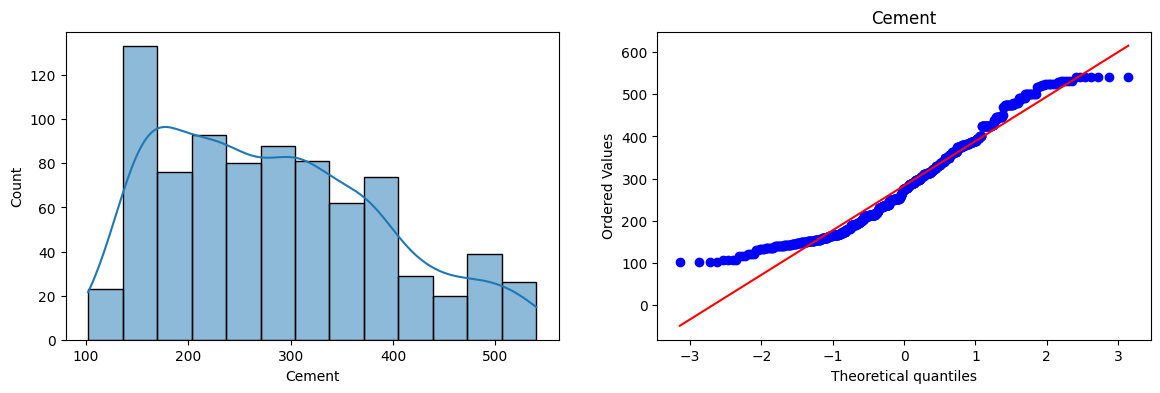

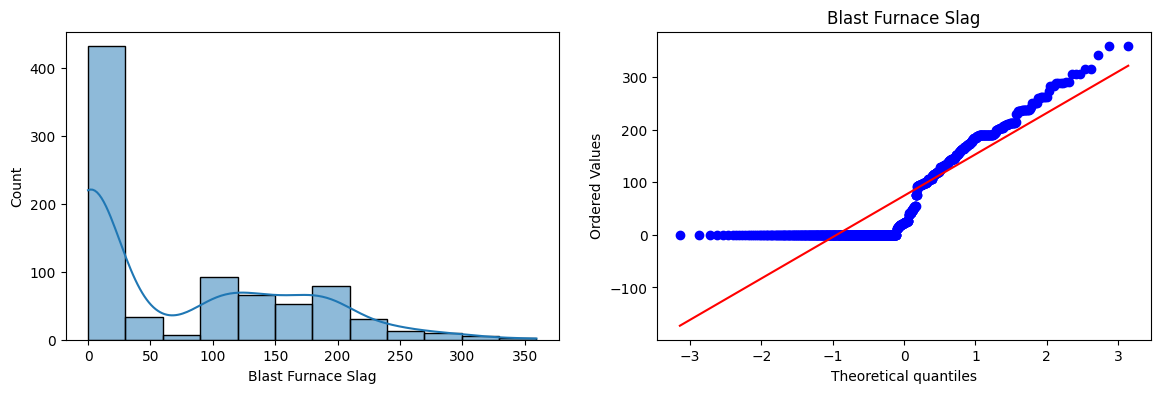

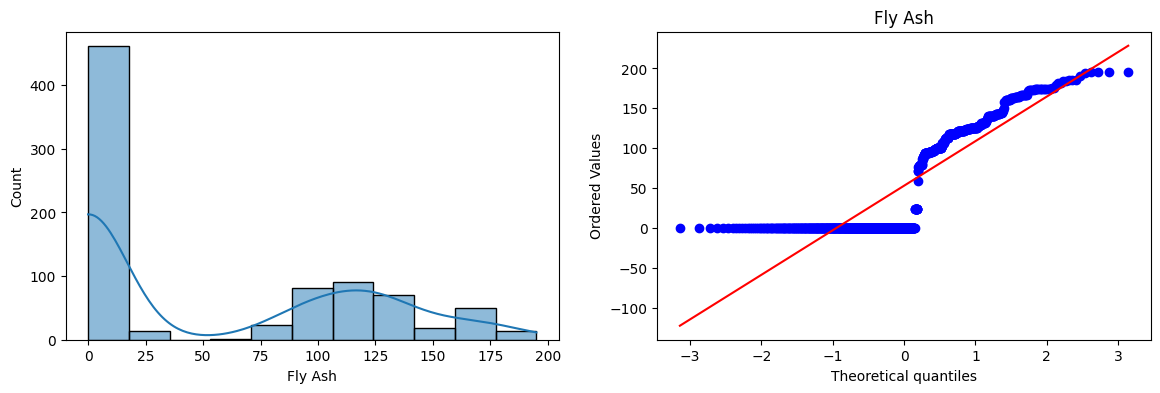

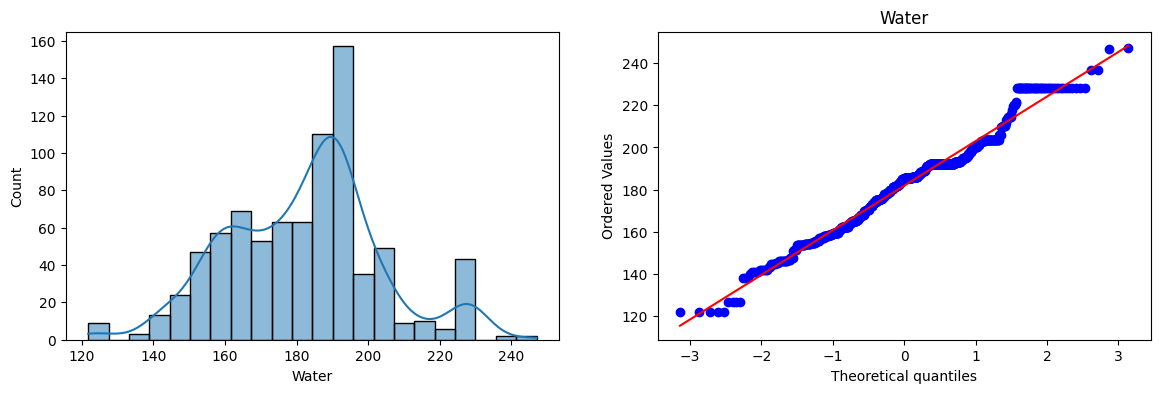

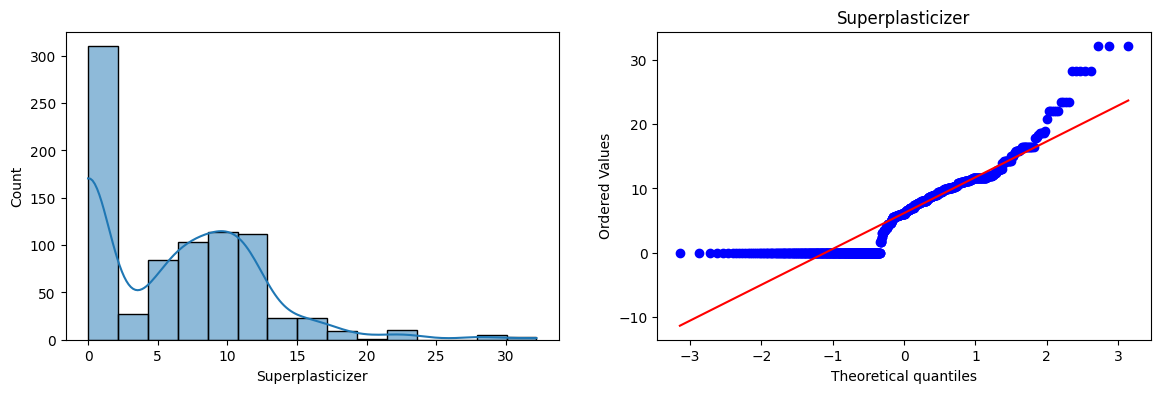

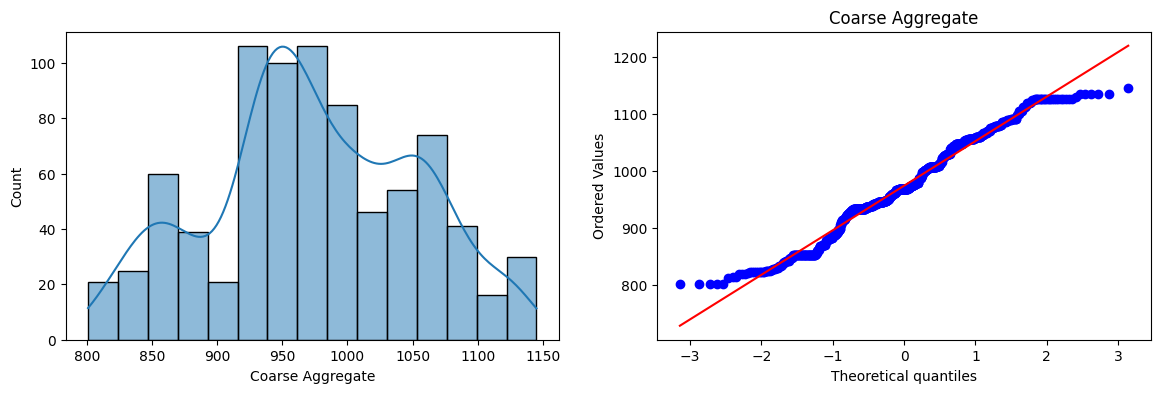

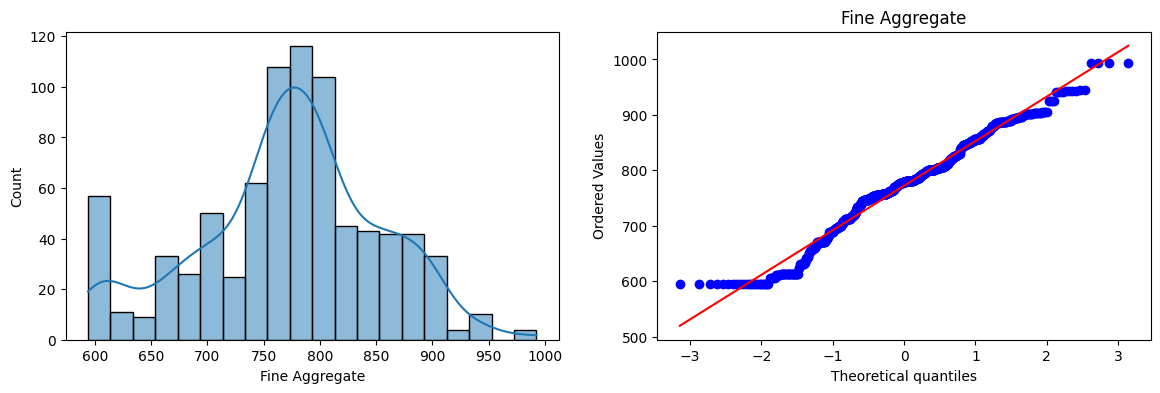

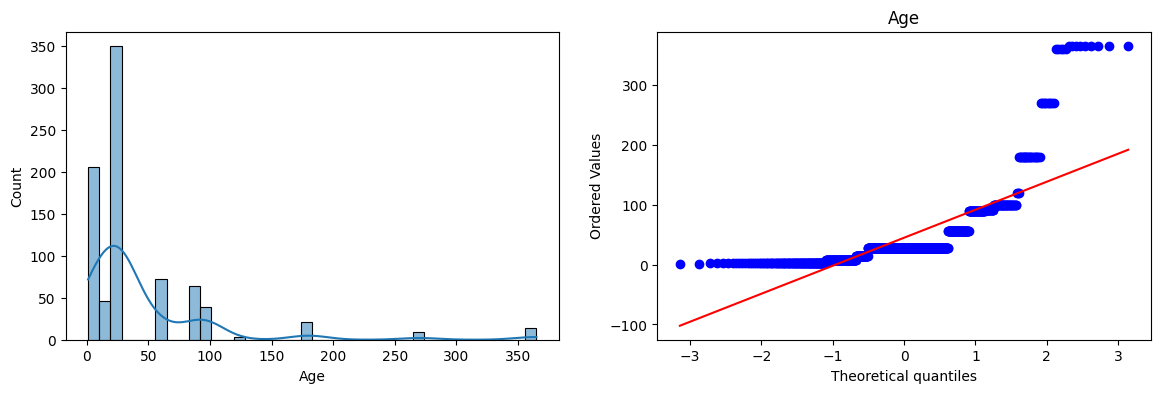

In [32]:
#Plotting distplots without any trasformation
for col in X_train.columns:
    plt.figure(figsize=(14,4))
    plt.subplot(121)
    # sns.displot(X_train[col])
#     What it shows:
# Histogram → frequency of values
# KDE curve → smooth distribution line
    sns.histplot(X_train[col], kde=True)

    plt.subplot(122)
    stats.probplot(X_train[col],dist="norm",plot=plt)
    plt.title(col)
    plt.show()

Histogram	Distribution shape
KDE	Smooth trend
QQ Plot	Normality check


In [40]:
# Applying Box-Cox trasform
pt = PowerTransformer(method='box-cox')
X_train_trasformed = pt.fit_transform(X_train+0.00001)# to change zero values col to nonzero
X_test_transformed = pt.transform(X_test+0.00001)
pd.DataFrame({'cols' : X_train.columns,'box_cox_lambdas':pt.lambdas_})


,cols,box_cox_lambdas
0,Cement,0.177025
1,Blast Furnace Slag,0.027842
2,Fly Ash,-0.044554
3,Water,0.772682
4,Superplasticizer,0.113892
5,Coarse Aggregate,1.129813
6,Fine Aggregate,1.782018
7,Age,0.066630


In [42]:

# Applying linear regression on transformed data

lr = LinearRegression()
lr.fit(X_train_trasformed,y_train)

y_pred2 = lr.predict(X_test_transformed)

r2_score(y_test,y_pred2)



0.8054599363621681

In [43]:


# Using cross val score

pt = PowerTransformer(method='box-cox')
X_transformed = pt.fit_transform(X+0.0000001)

lr = LinearRegression()
np.mean(cross_val_score(lr,X_transformed,y,scoring='r2'))#"Train and test the model multiple times on different splits and return the average R² score"



np.float64(0.6658537940290383)

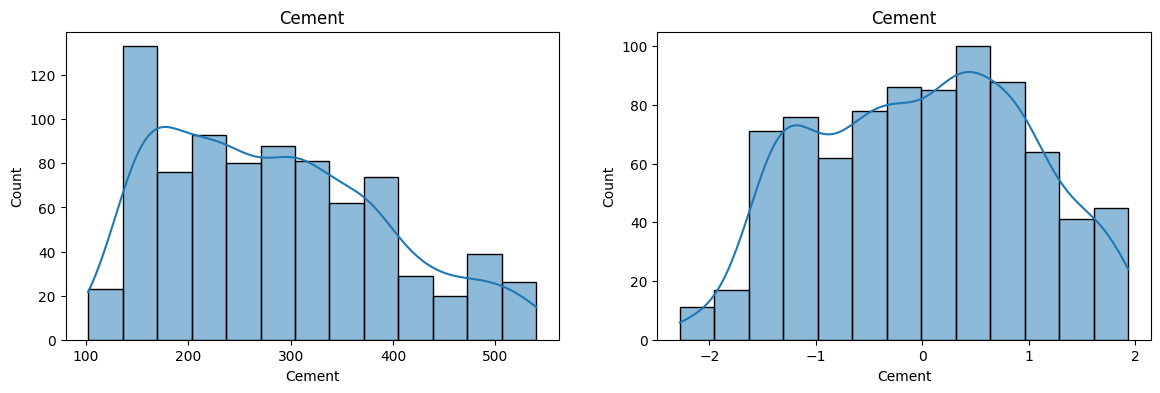

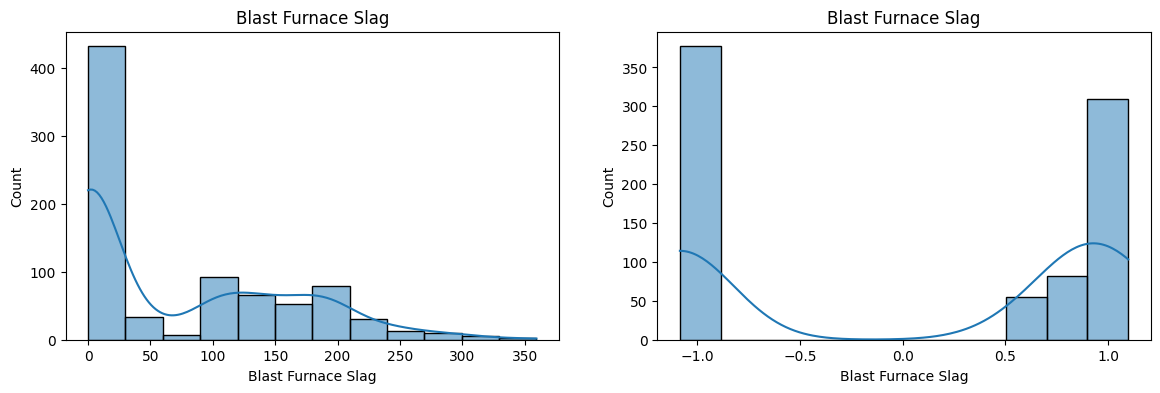

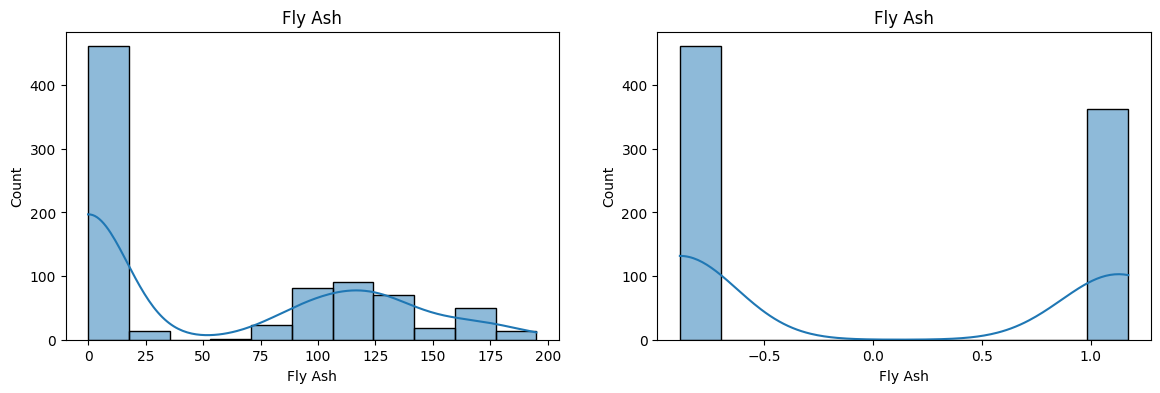

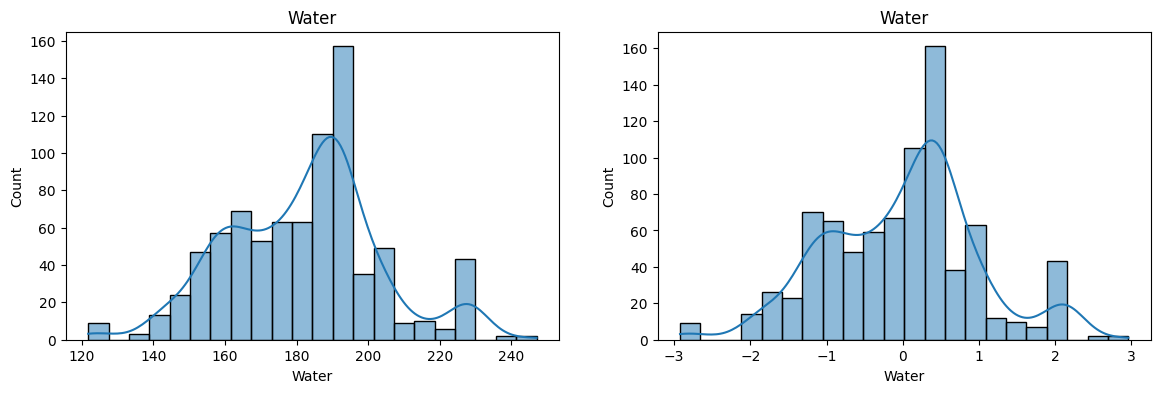

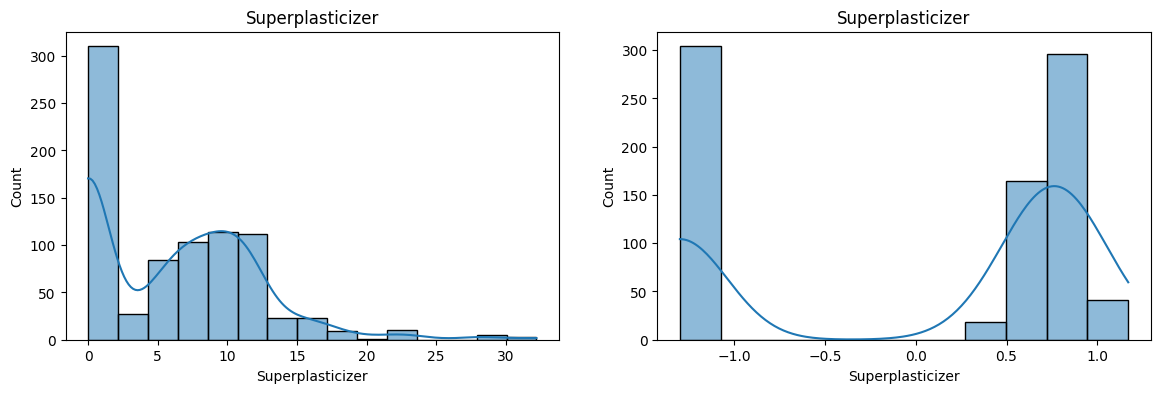

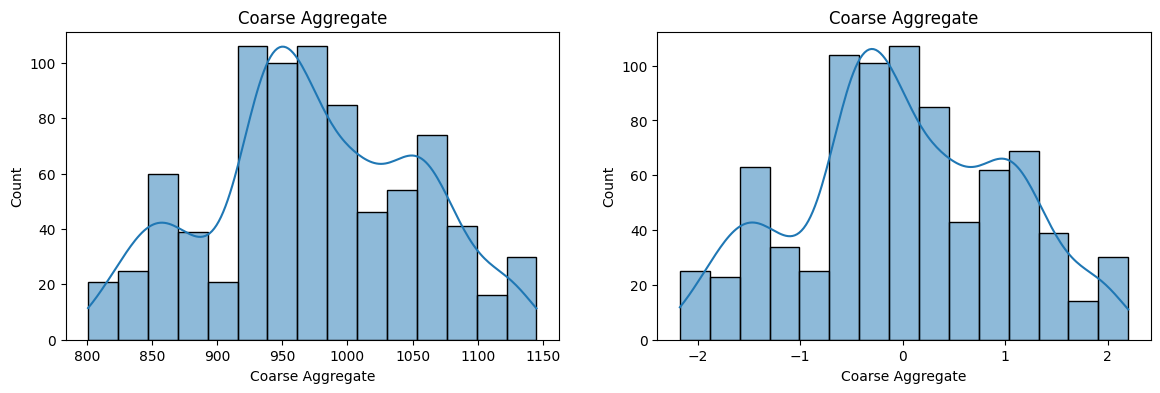

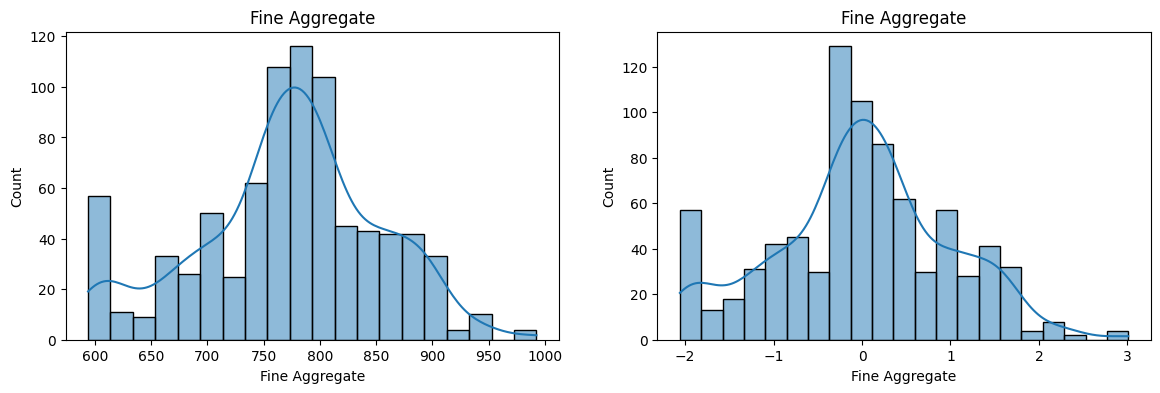

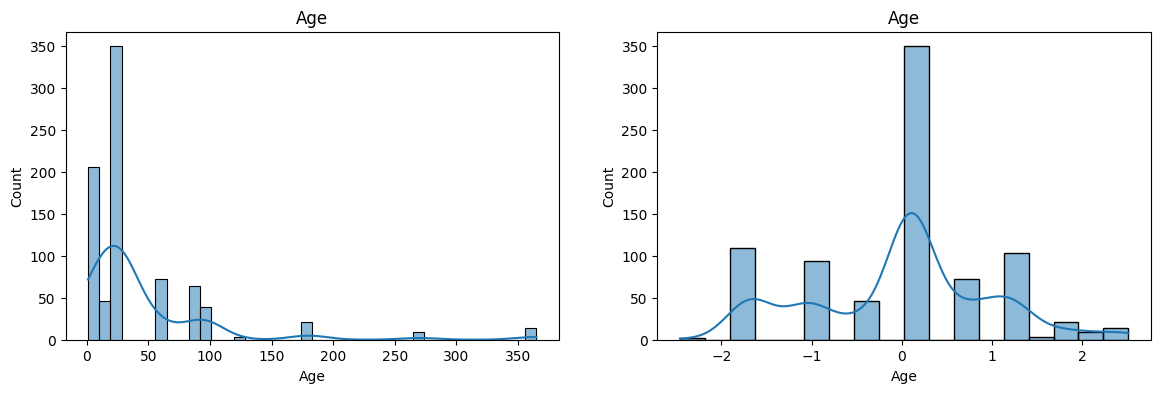

In [52]:
# Before and after comparision for Box-Cox Plot
X_train_trasformed = pd.DataFrame(X_train_trasformed,columns=X_train.columns)

for col in X_train_trasformed.columns:
    plt.figure(figsize=(14,4))
    plt.subplot(121)
    sns.histplot(X_train[col],kde=True)
    plt.title(col)

    plt.subplot(122)
    sns.histplot(X_train_trasformed[col],kde=True)
    plt.title(col)

    plt.show()